<a href="https://colab.research.google.com/github/kelvincleophace0309/COU07506-labs/blob/main/COU07506_Week04_240141484517.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# COU 07506 DSP, Week 04: z-Transform Laboratory (Poles, Zeros and Stability)
Name: Kelvin K Cleophace
Registration No: 240141484517
Class: BENG24COE-1  Date: 25/11/2026

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
plt.rcParams["figure.figsize"] = (9, 3.5)

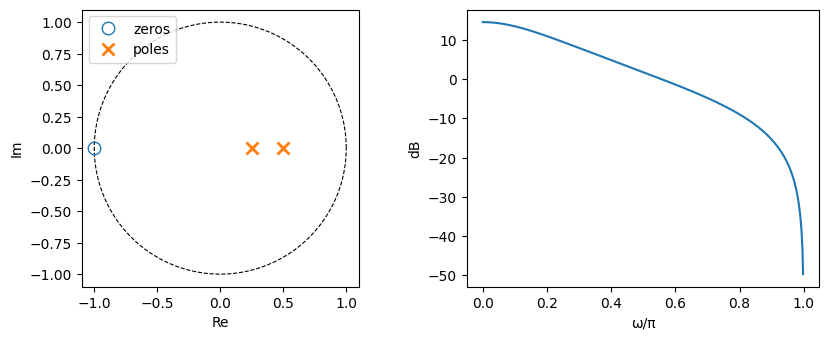

poles: [0.5  0.25]  stable: True


In [3]:
def zplane(b, a, ax=None):
    z, p, k = signal.tf2zpk(b, a)
    ax = ax or plt.gca()
    th = np.linspace(0, 2*np.pi, 400)
    ax.plot(np.cos(th), np.sin(th), "k--", lw=0.8)
    ax.plot(z.real, z.imag, "o", mfc="none", ms=9, label="zeros")
    ax.plot(p.real, p.imag, "x", ms=9, mew=2, label="poles")
    ax.set_aspect("equal"); ax.legend(loc="upper left"); ax.set_xlabel("Re"); ax.set_ylabel("Im")
    return z, p

b, a = [1, 1], [1, -0.75, 0.125]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
z, p = zplane(b, a, ax1)
w, H = signal.freqz(b, a, worN=512)
ax2.plot(w/np.pi, 20*np.log10(np.abs(H))); ax2.set_xlabel("ω/π"); ax2.set_ylabel("dB")
plt.show()
print("poles:", p, " stable:", np.all(np.abs(p) < 1))

In [4]:
# Pre-lab (b) and Task 4.2: H(z) = 1 / (1 - 0.75 z^-1 + 0.125 z^-2)
r, p, k = signal.residuez([1], [1, -0.75, 0.125])
print("residues", r, "poles", p)
n = np.arange(10)
x_pf = sum(ri * pi**n for ri, pi in zip(r, p)).real
impulse = np.zeros(10); impulse[0] = 1
x_lf = signal.lfilter([1], [1, -0.75, 0.125], impulse)
print("partial fractions match lfilter:", np.allclose(x_pf, x_lf))

# Same, for the Task 4.1 system with b = [1, 1]
r2, p2, k2 = signal.residuez([1, 1], [1, -0.75, 0.125])
print("\nresidues", r2, "poles", p2)
h_pf = sum(ri * pi**n for ri, pi in zip(r2, p2)).real
h_cf = 6*0.5**n - 5*0.25**n
print("matches 6(0.5)^n - 5(0.25)^n:", np.allclose(h_pf, h_cf))

# Pre-lab (a): poles of 1 / (1 - 0.9 z^-1 + 0.81 z^-2)
pa = np.roots([1, -0.9, 0.81])
print("\npre-lab (a) poles:", np.round(pa, 4), "| magnitude:", np.round(np.abs(pa), 4),
      "| stable:", np.all(np.abs(pa) < 1))

residues [-1.  2.] poles [0.25 0.5 ]
partial fractions match lfilter: True

residues [-5.  6.] poles [0.25 0.5 ]
matches 6(0.5)^n - 5(0.25)^n: True

pre-lab (a) poles: [0.45+0.7794j 0.45-0.7794j] | magnitude: [0.9 0.9] | stable: True


r =  0.5 | largest |h(n)| =    1.000 | last |h(39)| =   0.0000
r =  0.8 | largest |h(n)| =    1.131 | last |h(39)| =   0.0000
r = 0.95 | largest |h(n)| =    1.344 | last |h(39)| =   0.0000
r =  1.0 | largest |h(n)| =    1.414 | last |h(39)| =   0.0000
r = 1.05 | largest |h(n)| =    8.600 | last |h(39)| =   0.0000


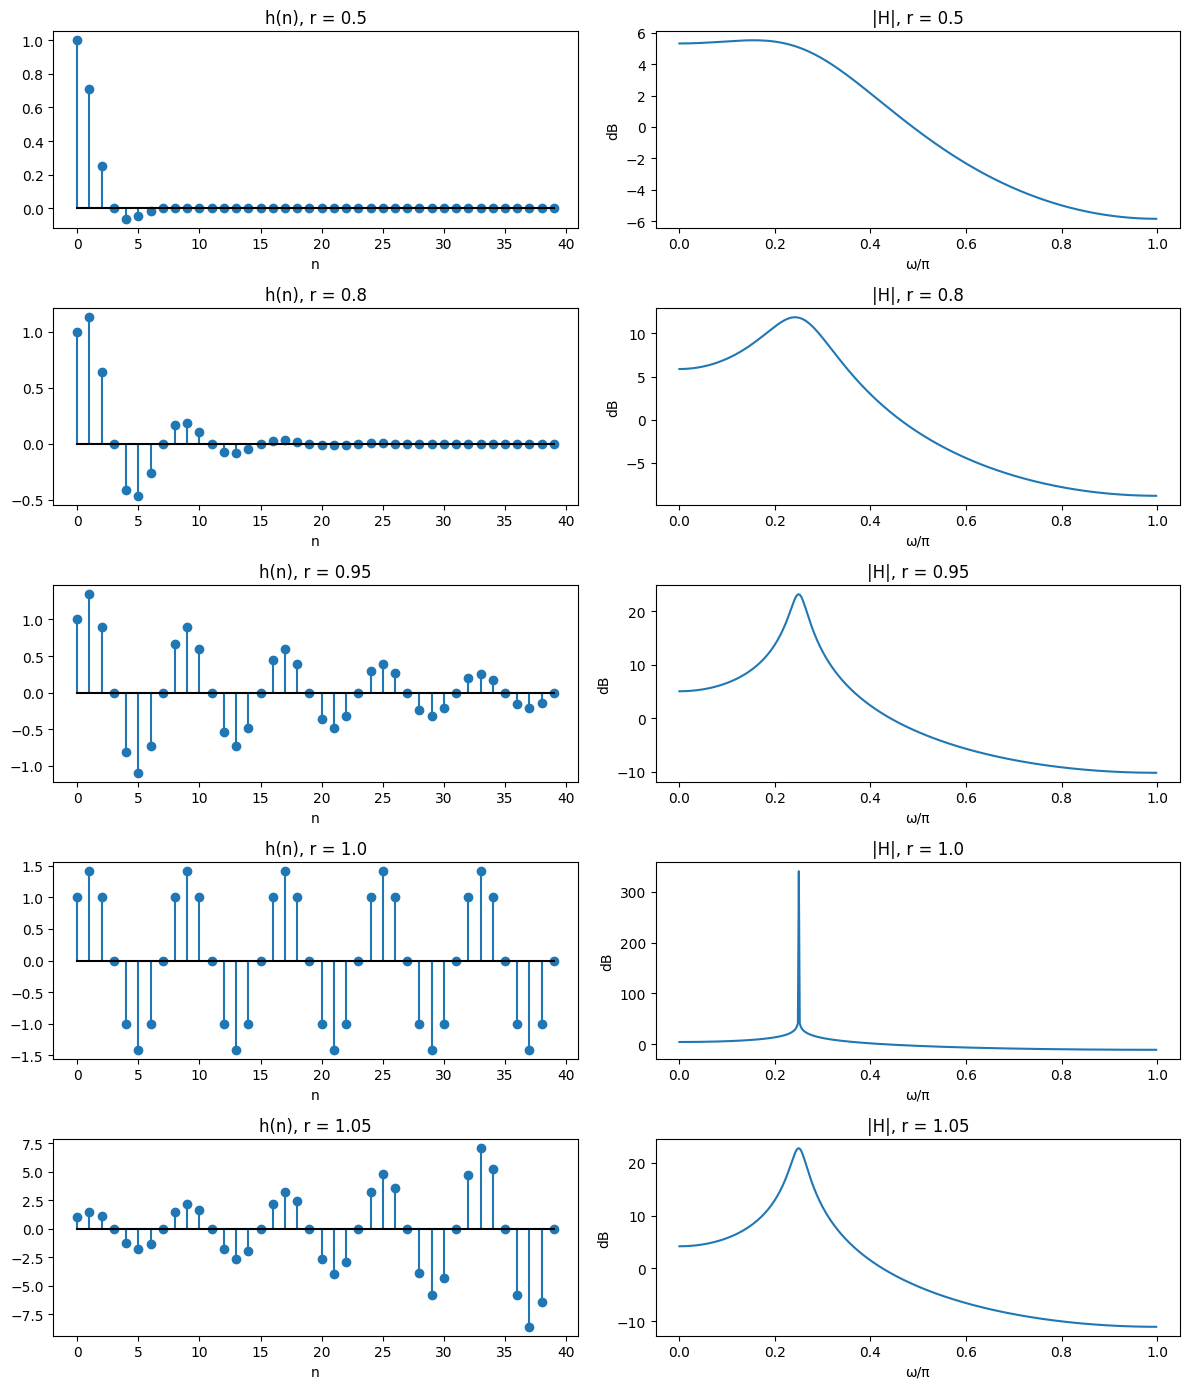

In [5]:
n = np.arange(40)
impulse = np.zeros(40); impulse[0] = 1
fig, axes = plt.subplots(5, 2, figsize=(12, 14))
for row, r in zip(axes, [0.5, 0.8, 0.95, 1.0, 1.05]):
    a = [1, -2*r*np.cos(np.pi/4), r**2]
    h = signal.lfilter([1], a, impulse)
    w, H = signal.freqz([1], a, worN=512)
    row[0].stem(n, h, basefmt="k-")
    row[0].set_title(f"h(n), r = {r}"); row[0].set_xlabel("n")
    row[1].plot(w/np.pi, 20*np.log10(np.abs(H) + 1e-12))
    row[1].set_title(f"|H|, r = {r}"); row[1].set_xlabel("ω/π"); row[1].set_ylabel("dB")
    print(f"r = {r:4} | largest |h(n)| = {np.max(np.abs(h)):8.3f} | last |h(39)| = {abs(h[-1]):8.4f}")
plt.tight_layout(); plt.show()

H1(z) [a]    | poles = [0.8+0.5j 0.8-0.5j] | max|p| = 0.9434 | status = Stable | |h[0]|=1.000, |h[29]|=3.0208e-01 | grows=False
H2(z) [b]    | poles = [2.  0.5] | max|p| = 2.0000 | status = Unstable | |h[0]|=1.000, |h[29]|=1.0737e+09 | grows=True
H3(z) [c]    | poles = [-1.   0.5] | max|p| = 1.0000 | status = Marginally Stable / Unstable | |h[0]|=1.000, |h[29]|=6.6667e-01 | grows=False
H4(z) [d]    | poles = [] | max|p| = 0.0000 | status = Stable | |h[0]|=1.000, |h[29]|=0.0000e+00 | grows=False


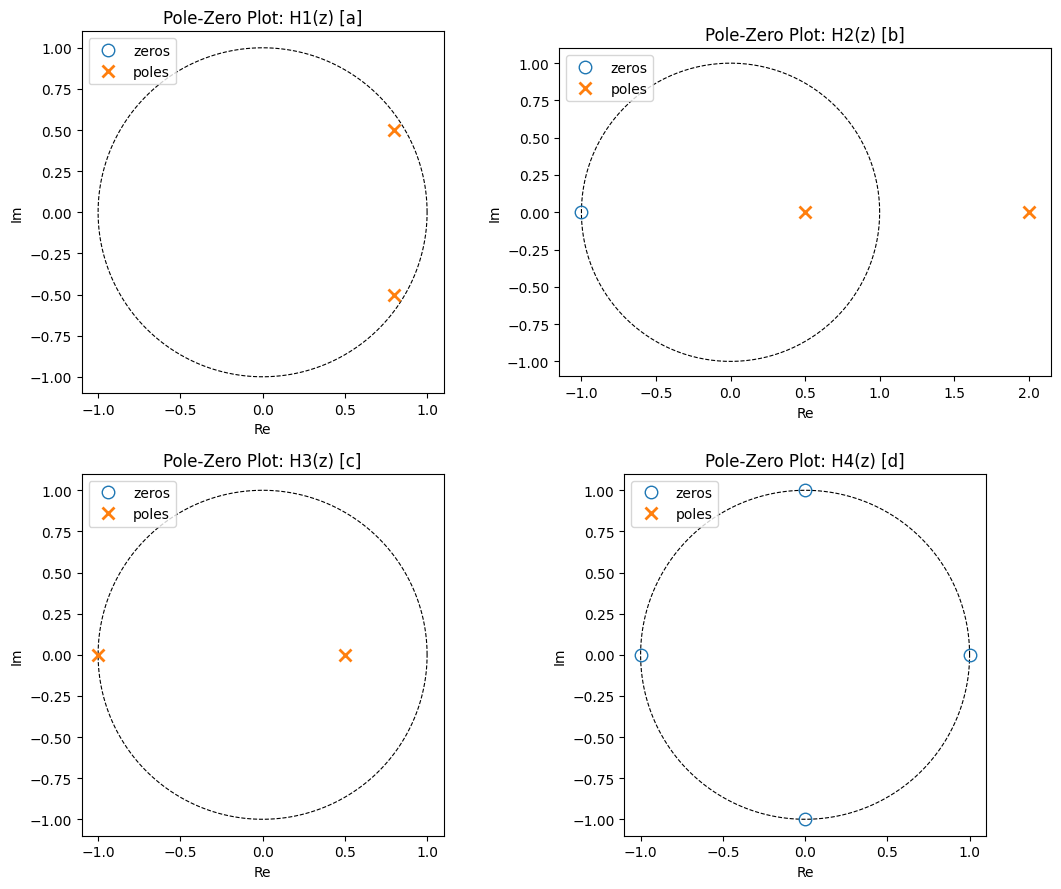

In [6]:
# Task 4.4: Stability of given systems
systems_4_4 = {
    "H1(z) [a]": ([1.0], [1.0, -1.6, 0.89]),
    "H2(z) [b]": ([1.0, 1.0], [1.0, -2.5, 1.0]),
    "H3(z) [c]": ([1.0], [1.0, 0.5, -0.5]),
    "H4(z) [d]": ([1.0, 0.0, 0.0, 0.0, -1.0], [1.0])
}

N_imp = 30
impulse = np.zeros(N_imp)
impulse[0] = 1.0
n_idx = np.arange(N_imp)

fig, axes = plt.subplots(2, 2, figsize=(11, 9))

for ax, (name, (b_sys, a_sys)) in zip(axes.flat, systems_4_4.items()):
    z_pts, p_pts = zplane(b_sys, a_sys, ax=ax)
    ax.set_title(f"Pole-Zero Plot: {name}")

    h_sys = signal.lfilter(b_sys, a_sys, impulse)
    max_pole_mag = np.max(np.abs(p_pts)) if len(p_pts) > 0 else 0.0

    # Causal BIBO stability requires all poles strictly inside unit circle (|p| < 1)
    is_strictly_stable = (len(p_pts) == 0) or np.all(np.abs(p_pts) < 1.0)
    grows = np.max(np.abs(h_sys[10:])) > np.max(np.abs(h_sys[:10])) * 2 if np.max(np.abs(h_sys[:10])) > 0 else False

    status_label = "Stable" if is_strictly_stable else ("Marginally Stable / Unstable" if np.isclose(max_pole_mag, 1.0) else "Unstable")

    print(f"{name:12s} | poles = {np.round(p_pts, 4)} | max|p| = {max_pole_mag:.4f} | "
          f"status = {status_label} | |h[0]|={abs(h_sys[0]):.3f}, |h[29]|={abs(h_sys[-1]):.4e} | grows={grows}")

plt.tight_layout()
plt.show()

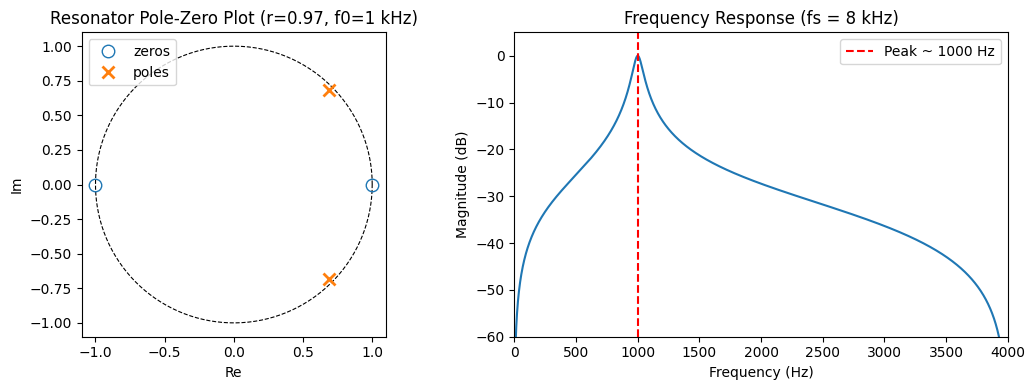

Zeros: [-1.  1.]
Poles: [0.6859+0.6859j 0.6859-0.6859j] | magnitudes: [0.97 0.97]
Measured peak frequency: 1000.0 Hz


In [7]:
# Task 4.5: Design a resonator peaking at 1 kHz (fs = 8 kHz, r = 0.97) with zeros at z = +-1
from IPython.display import Audio

fs_res = 8000.0
f_peak = 1000.0
r_res = 0.97
w0 = 2 * np.pi * f_peak / fs_res

# Zeros at z = +1 and z = -1 -> (1 - z^-1)(1 + z^-1) = 1 - z^-2
b_res = np.array([1.0, 0.0, -1.0])

# Poles at r * exp(+/- j * w0)
a_res = np.array([1.0, -2.0 * r_res * np.cos(w0), r_res**2])

# Normalize gain so peak magnitude at f_peak is 1.0 (0 dB)
_, H_peak_ref = signal.freqz(b_res, a_res, worN=[f_peak], fs=fs_res)
b_res = b_res / np.abs(H_peak_ref[0])

fig, (ax_pz, ax_fr) = plt.subplots(1, 2, figsize=(11, 4))
z_res, p_res = zplane(b_res, a_res, ax=ax_pz)
ax_pz.set_title("Resonator Pole-Zero Plot (r=0.97, f0=1 kHz)")

w_hz, H_res = signal.freqz(b_res, a_res, worN=2048, fs=fs_res)
mag_db = 20 * np.log10(np.abs(H_res) + 1e-12)
ax_fr.plot(w_hz, mag_db)
ax_fr.axvline(f_peak, color="r", linestyle="--", label=f"Peak ~ {w_hz[np.argmax(mag_db)]:.0f} Hz")
ax_fr.set_xlim(0, fs_res / 2)
ax_fr.set_ylim(-60, 5)
ax_fr.set_xlabel("Frequency (Hz)")
ax_fr.set_ylabel("Magnitude (dB)")
ax_fr.set_title("Frequency Response (fs = 8 kHz)")
ax_fr.legend()
plt.tight_layout()
plt.show()

print("Zeros:", np.round(z_res, 4))
print("Poles:", np.round(p_res, 4), "| magnitudes:", np.round(np.abs(p_res), 4))
print(f"Measured peak frequency: {w_hz[np.argmax(mag_db)]:.1f} Hz")

# Apply to 2 seconds of white noise
rng_res = np.random.default_rng(42)
t_noise = np.arange(0, 2.0, 1.0 / fs_res)
white_noise = rng_res.standard_normal(len(t_noise))
y_res = signal.lfilter(b_res, a_res, white_noise)
y_res = 0.5 * y_res / np.max(np.abs(y_res))  # safe playback level

Audio(y_res, rate=int(fs_res))

## Pre-lab
(a) For H(z) = 1 / (1 - 0.9 z^-1 + 0.81 z^-2), the poles are at p = 0.45 ± j0.7794. Since |p| = 0.9 < 1, both poles lie inside the unit circle, so the system is stable.
(b) The partial-fraction expansion of X(z) = 1 / [(1 - 0.5 z^-1)(1 - 0.25 z^-1)] is X(z) = 2 / (1 - 0.5 z^-1) - 1 / (1 - 0.25 z^-1), giving x(n) = [2(0.5)^n - (0.25)^n] u(n).

## Task 4.1: Pole-zero plot and frequency response
For b = [1, 1] and a = [1, -0.75, 0.125], there is a zero at z = -1 and poles at z = 0.5 and z = 0.25. Both poles are inside the unit circle (|p| < 1), so the system is stable. The zero at z = -1 creates a deep null at ω = π.

## Task 4.2: Inverse z-transform with residuez
signal.residuez returned residues [-1, 2] at poles [0.25, 0.5], matching my pre-lab answer (b) and agreeing with signal.lfilter. For b = [1, 1], it gave residues [-5, 6] at poles [0.25, 0.5], confirming h(n) = 6(0.5)^n - 5(0.25)^n.

## Task 4.3: Pole position and the impulse response
For r = 0.5, 0.8 and 0.95, h(n) decays to zero while the peak in |H(e^jω)| becomes taller and sharper as r increases. At r = 1.0, h(n) oscillates at a constant amplitude without decaying (marginally stable). At r = 1.05, h(n) grows without bound, so r = 1.05 is unstable.

## Task 4.4: Stability of given systems
(a) H1(z) has poles at 0.8 ± 0.5j (|p| = 0.9434 < 1) -> Stable, h(n) decays.
(b) H2(z) has poles at 2.0 and 0.5 (max |p| = 2.0 > 1) -> Unstable, h(n) grows rapidly.
(c) H3(z) has poles at -1.0 and 0.5 (max |p| = 1.0) -> Marginally stable / not strictly stable because a pole lies on the unit circle.
(d) H4(z) = 1 - z^-4 has no poles outside the origin (FIR) -> Stable, h(n) ends after 4 samples.

## Task 4.5: Design a resonator
Using ω0 = 2π(1000)/8000 = π/4 and r = 0.97 with zeros at z = ±1 gave poles at 0.6859 ± 0.6859j (|p| = 0.97) and zeros at -1 and +1. The frequency response peaked at 1000.0 Hz and dropped sharply at 0 Hz and 4000 Hz. Filtering white noise produced a narrowband 1 kHz ringing tone.

## Analysis Question 1
As r increases toward 1, the poles move closer to the unit circle, which narrows the resonance bandwidth and makes the peak sharper and taller. A smaller r moves the poles away from the unit circle, resulting in a wider, flatter resonance.

## Analysis Question 2
When a pole lies on the unit circle (|p| = 1), its term neither decays to zero nor grows exponentially. The impulse response h(n) sustains constant-amplitude oscillations forever, making the system marginally stable (and BIBO unstable if driven at the resonant frequency).

## Analysis Question 3
On the unit circle, z = +1 corresponds to DC (0 Hz) and z = -1 corresponds to the Nyquist frequency (fs/2 = 4 kHz). Placing zeros at z = ±1 puts nulls at both 0 Hz and 4 kHz to block very low and very high frequencies, while the poles at 1 kHz boost the middle band, creating a band-pass filter.

## Analysis Question 4
For 1 + a1 z^-1 + a2 z^-2, the stability triangle requires |a2| < 1, a1 + a2 > -1, and -a1 + a2 > -1:
(a) a1 = -1.6, a2 = 0.89: |0.89| < 1, -1.6 + 0.89 = -0.71 > -1, and 1.6 + 0.89 = 2.49 > -1 -> Stable.
(b) a1 = -2.5, a2 = 1.0: a2 is not strictly less than 1 and -2.5 + 1.0 = -1.5 < -1 -> Unstable.
(c) a1 = 0.5, a2 = -0.5: a1 + a2 = -1.0 (on the boundary, not strictly > -1) -> Marginally stable / not strictly stable.

## AI-use statement
AI tools used: Claude

Used for: step-by-step guidance on running Tasks 4.1 to 4.5 in Colab and verifying analysis answers
How I verified the output: compared my results with the expected values in the lab manual, checked residuez against lfilter and 6(0.5)^n - 5(0.25)^n, and verified pole locations, h(n) behavior and the 1000 Hz resonator peak
I confirm that I understand and can explain all submitted code.